# ESC-50 — Classificação binária com Gaussian Naive Bayes

**Objetivo:** distinguir sons **normais (classes 0–19 → 0)** de sons **anômalos (classes 40–49 → 1)**.

Este notebook mantém a **extração dos atributos do projeto original** e implementa um **baseline supervisionado** com `GaussianNB`. Ao contrário de GMM/KDE treinados somente com sons normais, o Naive Bayes **aprende com exemplos de ambas as categorias**. Por isso, a comparação entre os métodos deve reconhecer essa diferença de supervisão.

**Protocolo reprodutível:** folds oficiais do ESC-50: **1–3** para treinamento e seleção de atributos, **4** para escolha dos hiperparâmetros e do limiar, **5** reservado ao teste final. Não se consulta o teste durante a otimização.

**Ordem de execução:** rode as células na sequência, de cima para baixo. O clone do ESC-50 requer conexão com a internet (por exemplo, Google Colab).

## 1. Carregamento e extração das características

As funções abaixo foram preservadas do seu notebook original (Experimento C: MFCCs, deltas, ZCR, frequência dominante, pulsos, silêncio, entropia, fluxo espectral e outras estatísticas).

In [1]:
import os
import subprocess
if not os.path.isdir('ESC-50/meta'):
    subprocess.run(['git','clone','https://github.com/karolpiczak/ESC-50.git'], check=True)
else:
    print('ESC-50 já está presente; clonagem ignorada.')

In [2]:
import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import entropy
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, roc_curve

### 1. Upload do Dataset

In [3]:
caminho_csv = 'ESC-50/meta/esc50.csv'
PASTA_AUDIO = 'ESC-50/audio/'

In [4]:
df_original = pd.read_csv(caminho_csv)

Categorias
Animais (Índices 0 a 9)
0: Dog / 1: Rooster / 2: Pig / 3: Cow / 4: Frog / 5: Cat / 6: Hen / 7: Insects (flying) / 8: Sheep / 9: Crow

 Paisagens Naturais e Sons de Água (Índices 10 a 19)
 10: Rain / 11: Sea waves / 12: Crackling fire / 13: Crickets / 14: Chirping birds / 15: Water drops / 16: Wind / 17: Pouring water / 18: Toilet flush (Descarga de vaso sanitário) / 19: Thunderstorm (Tempestade com trovoada)

 Ruídos Externos / Urbanos (Índices 40 a 49)
 40: Helicopter / 41: Chainsaw / 42: Siren / 43: Car horn / 44: Engine / 45: Train / 46: Church bells / 47: Airplane / 48: Fireworks / 49: Hand saw

In [5]:
df = df_original[(df_original['target'] <= 19) | (df_original['target'] >= 40)]

In [6]:
df.head()

,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A
5,1-101296-B-19.wav,1,19,thunderstorm,False,101296,B
8,1-103298-A-9.wav,1,9,crow,False,103298,A


In [7]:
df.shape

(1200, 7)

### 2. Ajustes do Dataset

In [8]:
SR = 16000
COLUNA_ARQUIVO = "filename"

In [9]:
def estatisticas(vetor, prefixo):
    """
    Transforma uma série temporal em características por áudio.
    """
    vetor = np.asarray(vetor).flatten()

    return {
        f"{prefixo}_mean": np.mean(vetor),
        f"{prefixo}_std": np.std(vetor),
        f"{prefixo}_median": np.median(vetor),
        f"{prefixo}_min": np.min(vetor),
        f"{prefixo}_max": np.max(vetor),
    }

### 3. Experimento C: A + B

In [10]:
def extrair_experimento_C(caminho,  n_mfcc, sr=SR):

    y, sr = librosa.load(caminho, sr=sr, mono=True)

    features = {}

    # 1. MFCC
    mfcc = librosa.feature.mfcc(
        y=y,
        sr=sr,
        n_mfcc=n_mfcc
    )
    for i in range(n_mfcc):
        features.update(
            estatisticas(
                mfcc[i],
                f"mfcc_{i+1}"
            )
        )

    # 2. DELTA
    delta = librosa.feature.delta(mfcc)
    for i in range(n_mfcc):
        features.update(
            estatisticas(
                delta[i],
                f"delta_{i+1}"
            )
        )

    # 3. DELTA-DELTA
    delta_delta = librosa.feature.delta(
        mfcc,
        order=2
    )
    for i in range(n_mfcc):
        features.update(
            estatisticas(
                delta_delta[i],
                f"delta_delta_{i+1}"
            )
        )

    # 4. ZERO CROSSING RATE
    zcr = librosa.feature.zero_crossing_rate(y)[0]

    features.update(
        estatisticas(
            zcr,
            "zcr"
        )
    )

    # 5. SPECTRAL CENTROID
    centroid = librosa.feature.spectral_centroid(
        y=y,
        sr=sr
    )[0]
    features.update(
        estatisticas(
            centroid,
            "centroid"
        )
    )


    # 6. FREQUÊNCIA DOMINANTE
    espectro = np.abs(librosa.stft(y))
    frequencias = librosa.fft_frequencies(sr=sr)
    indice_dominante = np.argmax(
        espectro,
        axis=0
    )
    freq_dominante = frequencias[indice_dominante]
    features.update(estatisticas(freq_dominante, "freq_dominante"))

    # 7. PULSOS POR SEGUNDO
    # Usa onset detection.
    # Cada onset representa aproximadamente um evento/pulso.
    onset_frames = librosa.onset.onset_detect(y=y,sr=sr)
    duracao = librosa.get_duration(y=y, sr=sr)
    if duracao > 0:
        pulsos_por_segundo = len(onset_frames) / duracao
    else:
        pulsos_por_segundo = 0

    features["pulsos_por_segundo"] = pulsos_por_segundo

    # 8. SILÊNCIO
    rms = librosa.feature.rms(y=y)[0]
    threshold = np.max(rms) * 0.05
    frames_silenciosos = rms < threshold
    percentual_silencio = np.mean(
        frames_silenciosos
    )
    features["percentual_silencio"] = percentual_silencio

    # 9. ENTROPIA ESPECTRAL
    potencia = espectro ** 2
    soma = np.sum(
        potencia,
        axis=0,
        keepdims=True
    )

    # evita divisão por zero
    soma[soma == 0] = 1e-12
    probabilidade = potencia / soma

    entropia = entropy(
        probabilidade,
        axis=0
    )
    features.update(
        estatisticas(
            entropia,
            "entropia_espectral"
        )
    )

    # 10. FLUXO ESPECTRAL
    spectral_flux = librosa.onset.onset_strength(
        y=y,
        sr=sr
    )

    features.update(
        estatisticas(
            spectral_flux,
            "fluxo_espectral"
        )
    )

    return features

### 4. Dataframes Finais Gerados

In [11]:
resultados_C = []

for _, linha in df.iterrows():

    arquivo = linha[COLUNA_ARQUIVO]

    caminho = f"{PASTA_AUDIO}/{arquivo}"

    try:

        features_C = extrair_experimento_C(caminho, 5)

        # --------------------------------------------
        # Metadados
        # --------------------------------------------
        features_C["filename"] = arquivo

        # mantém a classe original
        if "target" in df.columns:
            features_C["target"] = linha["target"]

        if "category" in df.columns:
            features_C["category"] = linha["category"]

        resultados_C.append(features_C)

    except Exception as e:

        print(
            f"Erro em {arquivo}: {e}"
        )

In [12]:
df_C = pd.DataFrame(resultados_C)

print("\nExperimento C:")
print(df_C.shape)

print("\nPrimeiras colunas C:")
print(df_C.columns.tolist())


Experimento C:
(1200, 105)

Primeiras colunas C:
['mfcc_1_mean', 'mfcc_1_std', 'mfcc_1_median', 'mfcc_1_min', 'mfcc_1_max', 'mfcc_2_mean', 'mfcc_2_std', 'mfcc_2_median', 'mfcc_2_min', 'mfcc_2_max', 'mfcc_3_mean', 'mfcc_3_std', 'mfcc_3_median', 'mfcc_3_min', 'mfcc_3_max', 'mfcc_4_mean', 'mfcc_4_std', 'mfcc_4_median', 'mfcc_4_min', 'mfcc_4_max', 'mfcc_5_mean', 'mfcc_5_std', 'mfcc_5_median', 'mfcc_5_min', 'mfcc_5_max', 'delta_1_mean', 'delta_1_std', 'delta_1_median', 'delta_1_min', 'delta_1_max', 'delta_2_mean', 'delta_2_std', 'delta_2_median', 'delta_2_min', 'delta_2_max', 'delta_3_mean', 'delta_3_std', 'delta_3_median', 'delta_3_min', 'delta_3_max', 'delta_4_mean', 'delta_4_std', 'delta_4_median', 'delta_4_min', 'delta_4_max', 'delta_5_mean', 'delta_5_std', 'delta_5_median', 'delta_5_min', 'delta_5_max', 'delta_delta_1_mean', 'delta_delta_1_std', 'delta_delta_1_median', 'delta_delta_1_min', 'delta_delta_1_max', 'delta_delta_2_mean', 'delta_delta_2_std', 'delta_delta_2_median', 'delta_d

## 2. Divisão dos dados pelos folds oficiais (sem vazamento)

Nesta etapa os metadados `fold` são associados ao `df_C` pelo `filename`, sem reextrair os áudios. **Os 30 rótulos originais são mantidos somente para analisar os atributos** e, posteriormente, são mapeados para as classes binárias de interesse.

- **Treino (folds 1, 2 e 3):** sons normais **e** anômalos; empregado na seleção de atributos e ajuste do Naive Bayes.
- **Validação (fold 4):** ajuste de `var_smoothing`, probabilidades a priori e limiar.
- **Teste (fold 5):** avaliação final uma única vez.

In [13]:
import numpy as np
import pandas as pd
from sklearn.metrics import balanced_accuracy_score

# Associação segura dos folds ao resultado da extração
assert df_C['filename'].is_unique, 'Foram encontrados áudios repetidos em df_C.'
df_nb = df_C.merge(
    df_original[['filename', 'fold']],
    on='filename', how='left', validate='one_to_one'
).copy()

assert df_nb['fold'].notna().all(), 'Há áudios sem fold associado.'
assert set(df_nb['target'].unique()) == (set(range(20)) | set(range(40, 50))), (
    'Verifique a extração: classes normais (0-19) e anômalas (40-49) não estão completas.'
)

df_nb['rotulo_binario'] = (df_nb['target'] >= 40).astype(int)
treino_nb = df_nb.loc[df_nb['fold'].isin([1, 2, 3])].copy()
validacao_nb = df_nb.loc[df_nb['fold'] == 4].copy()
teste_nb = df_nb.loc[df_nb['fold'] == 5].copy()

assert not (set(treino_nb['filename']) & set(validacao_nb['filename']))
assert not (set(treino_nb['filename']) & set(teste_nb['filename']))
assert not (set(validacao_nb['filename']) & set(teste_nb['filename']))

for nome, parte in [('Treinamento',treino_nb),('Validação',validacao_nb),('Teste',teste_nb)]:
    freq = parte['rotulo_binario'].value_counts().reindex([0,1],fill_value=0)
    print(f'{nome:<14}: {len(parte):3d} áudios | normais = {freq[0]:3d} | anômalos = {freq[1]:3d}')

Treinamento   : 720 áudios | normais = 480 | anômalos = 240
Validação     : 240 áudios | normais = 160 | anômalos =  80
Teste         : 240 áudios | normais = 160 | anômalos =  80


## 3. ANOVA e Pearson usando **somente os folds de treinamento**

Aqui aplicamos a mesma lógica de seleção do projeto: **ANOVA entre as 30 classes originais**, ordenação dos atributos pelo F-score e remoção de redundâncias pela **correlação de Pearson** (|r| ≥ 0,80). Dessa forma, a seleção permanece comparável à metodologia anterior, mas não consulta os folds 4 e 5.

**Importante:** a ANOVA das 30 classes não é exatamente uma seleção otimizada para o rótulo binário; ela preserva a hipótese do experimento anterior. É uma escolha metodológica explícita para este baseline.

In [14]:
from sklearn.feature_selection import f_classif

# Selecionamos exclusivamente features numéricas presentes em df_C.
metadados = {'target', 'fold', 'rotulo_binario'}
colunas_features = [c for c in df_C.select_dtypes(include=np.number).columns if c not in metadados]

X_selecao = treino_nb[colunas_features].replace([np.inf, -np.inf], np.nan)
medianas_treino = X_selecao.median(numeric_only=True)
X_selecao = X_selecao.fillna(medianas_treino)
if X_selecao.isna().any().any():
    raise ValueError('Algumas features ficaram inteiramente vazias; examine as colunas com NaN.')

# Mesmos rótulos multiclasse (0..19 e 40..49) do experimento original
F, valores_p = f_classif(X_selecao, treino_nb['target'])
ranking_nb = (
    pd.DataFrame({'atributo':colunas_features,'F_score':F,'p_value':valores_p})
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=['F_score'])
    .sort_values('F_score',ascending=False)
    .reset_index(drop=True)
)

print('Top 15 atributos por ANOVA — apenas folds 1–3:')
display(ranking_nb.head(15))

Top 15 atributos por ANOVA — apenas folds 1–3:


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [100] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


,atributo,F_score,p_value
0,delta_delta_3_max,41.252094,4.731697e-130
1,delta_delta_1_min,39.233264,1.951060e-125
2,delta_delta_1_std,38.780777,2.208993e-124
3,fluxo_espectral_std,38.478400,1.128692e-123
4,delta_3_max,37.829824,3.830003e-122
5,fluxo_espectral_max,36.892331,6.655710e-120
6,delta_delta_3_min,35.843053,2.343824e-117
7,delta_3_std,35.776027,3.420244e-117
8,delta_delta_3_std,34.360412,1.102712e-113
9,delta_1_std,33.471843,1.934189e-111


In [15]:
limiar_correlacao = 0.80
top_30 = ranking_nb.head(30)['atributo'].tolist()
matriz_corr_nb = X_selecao[top_30].corr(method='pearson')

atributos_sem_redundancia = []
for atributo in top_30:
    # Respeita a ordem do ranking: prevalece quem tem F-score maior
    if not any(
        pd.notna(matriz_corr_nb.loc[atributo, mantido])
        and abs(matriz_corr_nb.loc[atributo, mantido]) >= limiar_correlacao
        for mantido in atributos_sem_redundancia
    ):
        atributos_sem_redundancia.append(atributo)

# Escolha dinâmica no treino (não são usados os 12 nomes calculados sobre todos os folds)
atributos_finais = atributos_sem_redundancia[:12]
if len(atributos_finais) < 12:
    print(f'Atenção: restaram {len(atributos_finais)} atributos depois de Pearson; usaremos todos.')
assert atributos_finais, 'Nenhum atributo disponível para o modelo.'

print(f'Top 30 inicial: {len(top_30)} | Após Pearson: {len(atributos_sem_redundancia)}')
print('Features efetivamente usadas pelo Naive Bayes:')
for i, nome in enumerate(atributos_finais,1):
    print(f'{i:2d}. {nome}')

display(matriz_corr_nb.loc[atributos_finais,atributos_finais].round(2))

Atenção: restaram 9 atributos depois de Pearson; usaremos todos.
Top 30 inicial: 30 | Após Pearson: 9
Features efetivamente usadas pelo Naive Bayes:
 1. delta_delta_3_max
 2. delta_delta_1_min
 3. mfcc_3_min
 4. delta_4_std
 5. mfcc_3_std
 6. mfcc_1_mean
 7. delta_delta_2_max
 8. centroid_max
 9. mfcc_2_max


,delta_delta_3_max,delta_delta_1_min,mfcc_3_min,delta_4_std,mfcc_3_std,mfcc_1_mean,delta_delta_2_max,centroid_max,mfcc_2_max
delta_delta_3_max,1.00,-0.63,-0.64,0.72,0.78,-0.44,0.62,0.39,-0.05
delta_delta_1_min,-0.63,1.00,0.35,-0.53,-0.49,0.49,-0.70,-0.38,-0.06
mfcc_3_min,-0.64,0.35,1.00,-0.53,-0.76,0.19,-0.35,-0.13,0.04
delta_4_std,0.72,-0.53,-0.53,1.00,0.61,-0.33,0.63,0.41,0.00
mfcc_3_std,0.78,-0.49,-0.76,0.61,1.00,-0.42,0.47,0.28,-0.02
mfcc_1_mean,-0.44,0.49,0.19,-0.33,-0.42,1.00,-0.45,-0.37,-0.01
delta_delta_2_max,0.62,-0.70,-0.35,0.63,0.47,-0.45,1.00,0.52,0.02
centroid_max,0.39,-0.38,-0.13,0.41,0.28,-0.37,0.52,1.00,-0.58
mfcc_2_max,-0.05,-0.06,0.04,0.00,-0.02,-0.01,0.02,-0.58,1.00


## 4. Preparação dos dados para a classificação binária

`GaussianNB` modela a distribuição de **cada atributo dentro de cada classe** como uma gaussiana e assume independência condicional entre os atributos. Pearson remove correlações lineares altas, mas **não garante independência**, portanto essa hipótese precisa ser tratada como uma aproximação.

O imputador e a transformação das features serão ajustados exclusivamente sobre o conjunto de treino. Testaremos dois tipos: `StandardScaler` e `PowerTransformer` (Yeo-Johnson), que deixa atributos assimétricos (pulsos/s, silêncio, desvios-padrão, máx/mín) mais próximos de uma gaussiana — a hipótese central do `GaussianNB`. Ambos deixam as features com variância 1, o que dá estabilidade à interpretação de `var_smoothing`.

**Dois modos de treino do `GaussianNB`:**
- `binario`: duas gaussianas por atributo (normal x anomalia). Cada "classe" mistura sons muito diferentes (cachorro, chuva, trovão... x motor, sirene, serra...), e uma única gaussiana representa mal esse "guarda-chuva".
- `30_classes`: o **mesmo** `GaussianNB`, mas treinado com os 30 rótulos originais (uma gaussiana por atributo *por som*). O score final é consolidado somando as probabilidades posteriores das classes 40–49: `P(anomalia|x) = Σ P(classe c|x), c ∈ 40..49`. É a mesma lição do GMM (modelar cada classe separadamente), só que dentro de um único modelo.

In [16]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, recall_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, roc_curve
)
import matplotlib.pyplot as plt

X_treino = treino_nb[atributos_finais].to_numpy(dtype=float)
X_val = validacao_nb[atributos_finais].to_numpy(dtype=float)
X_teste = teste_nb[atributos_finais].to_numpy(dtype=float)
y_treino = treino_nb['rotulo_binario'].to_numpy(dtype=int)
y_treino30 = treino_nb['target'].to_numpy(dtype=int)  # 30 rótulos originais (só para o modo '30_classes')
y_val = validacao_nb['rotulo_binario'].to_numpy(dtype=int)
y_teste = teste_nb['rotulo_binario'].to_numpy(dtype=int)

# Infinitos não devem entrar no pipeline; NaNs são tratados pelo imputador.
for nome, matriz in [('treino',X_treino), ('validação',X_val), ('teste',X_teste)]:
    if np.isinf(matriz).any():
        raise ValueError(f'Encontrado +/-inf nas features de {nome}.')

print('X treino:',X_treino.shape,'| X val:',X_val.shape,'| X teste:',X_teste.shape)
print('Distribuição de rótulos: [normal, anomalia]')
print('Treino:',np.bincount(y_treino),'Validação:',np.bincount(y_val),'Teste:',np.bincount(y_teste))

def construir_naive_bayes(var_smoothing=1e-3, transformacao='potencia'):
    """Cria novo pipeline; sem vazamento entre ajuste e avaliação."""
    if transformacao == 'potencia':
        escala = PowerTransformer(method='yeo-johnson', standardize=True)
    elif transformacao == 'padrao':
        escala = StandardScaler()
    else:
        raise ValueError(f'Transformação desconhecida: {transformacao}')

    return Pipeline([
        ('imputacao', SimpleImputer(strategy='median')),
        ('padronizacao', escala),
        ('modelo', GaussianNB(var_smoothing=var_smoothing))
    ])

def prob_anomalia(modelo, X):
    """P(anomalia|x). Binário: coluna 1. 30 classes: soma das posteriores das classes 40-49."""
    p = modelo.predict_proba(X)
    c = modelo.classes_
    return p[:, 1] if len(c) == 2 else p[:, c >= 40].sum(axis=1)


X treino: (720, 9) | X val: (240, 9) | X teste: (240, 9)
Distribuição de rótulos: [normal, anomalia]
Treino: [480 240] Validação: [160  80] Teste: [160  80]


## 5. Busca de hiperparâmetros **somente na validação**

A busca é feita em **duas etapas**, para reduzir o risco de "decorar" o fold 4 (são só ~240 áudios):

1. **Modelo** (`modo`, `transformacao`, `var_smoothing`): escolhido pela **ROC-AUC de validação**, que não depende de limiar.
2. **Limiar** de P(anomalia): escolhido depois, para o modelo vencedor, no ponto da curva ROC que maximiza a **acurácia balanceada** (índice de Youden: TPR − FPR).

Observações:
- A *prior* deixou de ser hiperparâmetro: no caso binário, trocar a prior equivale a deslocar o limiar, então testar as duas só dobrava a grade sem ganho.
- `var_smoothing` é somado à variância (já em escala ~1), então valores abaixo de ~1e-3 são praticamente iguais; a grade foi deslocada para 1e-4 a 1. Com ~24 áudios por som no modo `30_classes`, as variâncias por classe são ruidosas e a regularização importa mais.
- O Naive Bayes costuma ser **superconfiante** (probabilidades perto de 0 ou 1), por isso o limiar é buscado nos scores observados, e não numa grade fixa de 0,10 a 0,90.

O fold 5 não participa de nenhuma etapa.

In [17]:
from itertools import product

smoothing_candidatos = np.logspace(-4, 0, 9)
y_fit = {'binario': y_treino, '30_classes': y_treino30}

# Etapa 1: escolher o modelo pela ROC-AUC de validação (independe do limiar)
linhas_busca, modelos_ajustados = [], {}
for modo, transf, smoothing in product(y_fit, ['padrao', 'potencia'], smoothing_candidatos):
    modelo = construir_naive_bayes(float(smoothing), transf).fit(X_treino, y_fit[modo])
    modelos_ajustados[(modo, transf, float(smoothing))] = modelo
    linhas_busca.append({'modo': modo, 'transformacao': transf, 'var_smoothing': float(smoothing),
                         'roc_auc_val': roc_auc_score(y_val, prob_anomalia(modelo, X_val))})

resultados_validacao_nb = pd.DataFrame(linhas_busca).sort_values(
    'roc_auc_val', ascending=False).reset_index(drop=True)
print('TOP 10 — configurações na validação (fold 4), por ROC-AUC:')
display(resultados_validacao_nb.head(10).round(4))
print('Melhor ROC-AUC por modo/transformação:')
display(resultados_validacao_nb.groupby(['modo', 'transformacao'])['roc_auc_val'].max().round(4))

melhor_nb = resultados_validacao_nb.iloc[0]
modo_escolhido, transf_escolhida = melhor_nb['modo'], melhor_nb['transformacao']
smoothing_escolhido = float(melhor_nb['var_smoothing'])
modelo_final_nb = modelos_ajustados[(modo_escolhido, transf_escolhida, smoothing_escolhido)]

# Etapa 2: limiar do modelo vencedor (maximiza TPR - FPR = acurácia balanceada)
fpr_v, tpr_v, limiares_v = roc_curve(y_val, prob_anomalia(modelo_final_nb, X_val))
limiar_escolhido = float(limiares_v[np.argmax(tpr_v - fpr_v)])

print('\nCONFIGURAÇÃO FINAL — DEFINIDA ANTES DE CONSULTAR O TESTE')
print('Modo:', modo_escolhido, '| Transformação:', transf_escolhida)
print('var_smoothing:', f'{smoothing_escolhido:.2e}')
print('Limiar para prever ANOMALIA:', f'{limiar_escolhido:.4g}')
print('ROC-AUC de validação:', f"{melhor_nb['roc_auc_val']:.4f}")
print('Acurácia balanceada de validação:', f'{(1 + (tpr_v - fpr_v).max()) / 2:.4f}')

TOP 10 — configurações na validação (fold 4), por ROC-AUC:


,modo,transformacao,var_smoothing,roc_auc_val
0,30_classes,potencia,0.0032,0.8911
1,30_classes,potencia,0.0003,0.8909
2,30_classes,potencia,0.0010,0.8909
3,30_classes,potencia,0.0001,0.8909
4,30_classes,potencia,0.0100,0.8908
5,30_classes,potencia,0.0316,0.8906
6,30_classes,potencia,0.1000,0.8888
7,30_classes,potencia,0.3162,0.8791
8,30_classes,padrao,0.1000,0.8777
9,30_classes,padrao,0.0316,0.8753


Melhor ROC-AUC por modo/transformação:


modo        transformacao
30_classes  padrao           0.8777
            potencia         0.8911
binario     padrao           0.7553
            potencia         0.7453
Name: roc_auc_val, dtype: float64


CONFIGURAÇÃO FINAL — DEFINIDA ANTES DE CONSULTAR O TESTE
Modo: 30_classes | Transformação: potencia
var_smoothing: 3.16e-03
Limiar para prever ANOMALIA: 0.2425
ROC-AUC de validação: 0.8911
Acurácia balanceada de validação: 0.8469


## 6. Análise da validação

Visualizar as probabilidades estimadas de anomalia no fold 4 ajuda a perceber se as duas classes ficam separadas, sem consultar o teste.

RELATÓRIO DE VALIDAÇÃO (fold 4):
              precision    recall  f1-score   support

      Normal       0.94      0.79      0.86       160
    Anomalia       0.69      0.90      0.78        80

    accuracy                           0.83       240
   macro avg       0.81      0.85      0.82       240
weighted avg       0.86      0.83      0.83       240



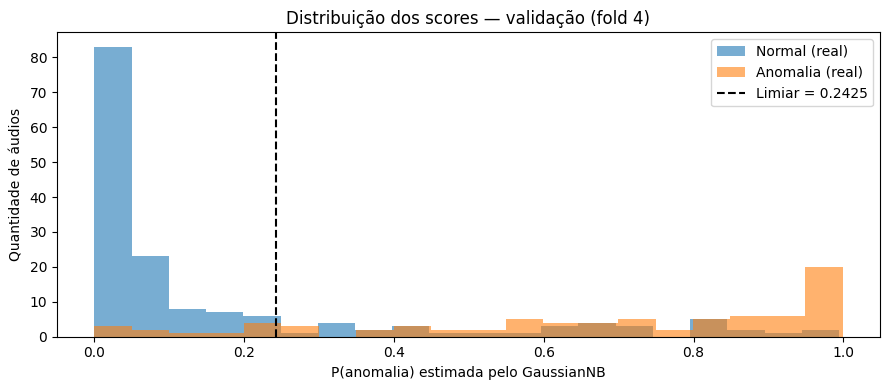

In [18]:
prob_val = prob_anomalia(modelo_final_nb, X_val)
pred_val_final = (prob_val >= limiar_escolhido).astype(int)

print('RELATÓRIO DE VALIDAÇÃO (fold 4):')
print(classification_report(y_val,pred_val_final,labels=[0,1],
                            target_names=['Normal','Anomalia'],zero_division=0))

plt.figure(figsize=(9,4))
plt.hist(prob_val[y_val==0],bins=20,alpha=.6,label='Normal (real)')
plt.hist(prob_val[y_val==1],bins=20,alpha=.6,label='Anomalia (real)')
plt.axvline(limiar_escolhido,color='black',linestyle='--',label=f'Limiar = {limiar_escolhido:.4g}')
plt.xlabel('P(anomalia) estimada pelo GaussianNB')
plt.ylabel('Quantidade de áudios')
plt.title('Distribuição dos scores — validação (fold 4)')
plt.legend()
plt.tight_layout()
plt.show()

## 7. Teste final — fold 5 (sem ajuste posterior)

O modelo, as features, os hiperparâmetros e o limiar foram congelados na etapa anterior. Este é o **único conjunto a ser usado para a avaliação final**. Caso seja necessário modificar o modelo após examinar estes resultados, o fold 5 já não pode ser considerado um teste intocado dessa nova versão.

=== NAIVE BAYES — RESULTADOS NO TESTE (fold 5) ===
Acurácia:             0.7500
Acurácia balanceada: 0.7219
F1 macro:             0.7205
Recall normal:        0.8063
Recall anomalia:      0.6375
ROC-AUC:              0.8053

RELATÓRIO DE CLASSIFICAÇÃO:
              precision    recall  f1-score   support

      Normal       0.82      0.81      0.81       160
    Anomalia       0.62      0.64      0.63        80

    accuracy                           0.75       240
   macro avg       0.72      0.72      0.72       240
weighted avg       0.75      0.75      0.75       240



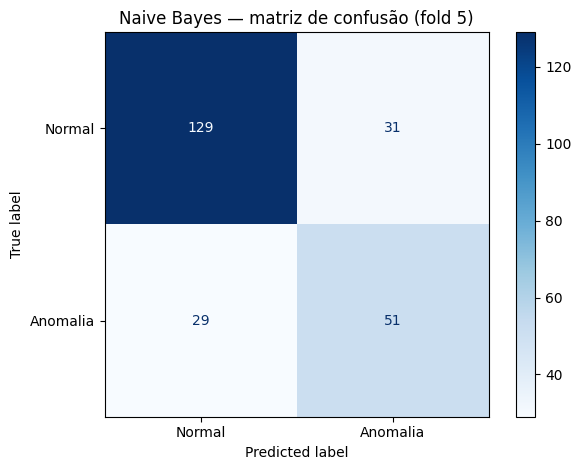

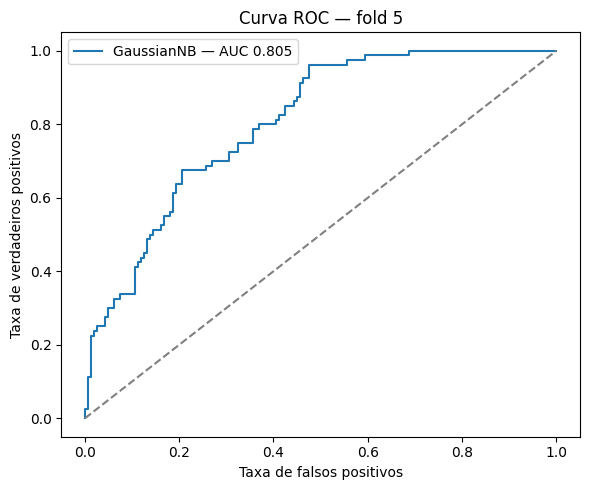

In [19]:
prob_teste = prob_anomalia(modelo_final_nb, X_teste)
pred_teste = (prob_teste >= limiar_escolhido).astype(int)

print('=== NAIVE BAYES — RESULTADOS NO TESTE (fold 5) ===')
print('Acurácia:            ',f'{accuracy_score(y_teste,pred_teste):.4f}')
print('Acurácia balanceada:',f'{balanced_accuracy_score(y_teste,pred_teste):.4f}')
print('F1 macro:            ',f'{f1_score(y_teste,pred_teste,average="macro",zero_division=0):.4f}')
print('Recall normal:       ',f'{recall_score(y_teste,pred_teste,pos_label=0,zero_division=0):.4f}')
print('Recall anomalia:     ',f'{recall_score(y_teste,pred_teste,pos_label=1,zero_division=0):.4f}')
print('ROC-AUC:             ',f'{roc_auc_score(y_teste,prob_teste):.4f}')

print('\nRELATÓRIO DE CLASSIFICAÇÃO:')
print(classification_report(y_teste,pred_teste,labels=[0,1],
                            target_names=['Normal','Anomalia'],zero_division=0))

cm = confusion_matrix(y_teste,pred_teste,labels=[0,1])
ConfusionMatrixDisplay(cm,display_labels=['Normal','Anomalia']).plot(cmap='Blues')
plt.title('Naive Bayes — matriz de confusão (fold 5)')
plt.tight_layout()
plt.show()

fpr,tpr,_ = roc_curve(y_teste,prob_teste)
plt.figure(figsize=(6,5))
plt.plot(fpr,tpr,label=f'GaussianNB — AUC {roc_auc_score(y_teste,prob_teste):.3f}')
plt.plot([0,1],[0,1],'--',color='gray')
plt.xlabel('Taxa de falsos positivos')
plt.ylabel('Taxa de verdadeiros positivos')
plt.title('Curva ROC — fold 5')
plt.legend()
plt.tight_layout()
plt.show()

## 8. Desempenho por classe original e análise dos erros

Mesmo classificando em apenas duas categorias (normal/anomalia), vale analisar **qual som original** falhou: cachorro, chuva, motor, sirene etc. Assim é possível descobrir se o desempenho global esconde dificuldades sistemáticas.

In [20]:
resultados_teste_nb = teste_nb[['filename','fold','target','category','rotulo_binario']].copy()
resultados_teste_nb['predito'] = pred_teste
resultados_teste_nb['prob_anomalia'] = prob_teste
resultados_teste_nb['acertou'] = resultados_teste_nb['rotulo_binario'] == resultados_teste_nb['predito']

por_classe_nb = (
    resultados_teste_nb.groupby(['target','category'],as_index=False)
    .agg(qtd_audios=('acertou','size'),taxa_acerto=('acertou','mean'),
         prob_media_anomalia=('prob_anomalia','mean'))
    .sort_values(['taxa_acerto','target'],ascending=[True,True])
)
print('ACERTO POR CLASSE ORIGINAL:')
display(por_classe_nb.round(4))

print('ÁUDIOS CLASSIFICADOS INCORRETAMENTE:')
display(resultados_teste_nb.loc[~resultados_teste_nb['acertou']].sort_values('prob_anomalia'))

# Baseline ingênuo: prever sempre a classe mais frequente no treino (normal=0)
y_pred_baseline = np.full_like(y_teste,fill_value=int(np.bincount(y_treino).argmax()))
comparacao_baseline = pd.DataFrame([
    {'modelo':'Sempre classe majoritária','acuracia':accuracy_score(y_teste,y_pred_baseline),
     'acuracia_balanceada':balanced_accuracy_score(y_teste,y_pred_baseline),
     'f1_macro':f1_score(y_teste,y_pred_baseline,average='macro',zero_division=0)},
    {'modelo':'GaussianNB otimizado (validação)','acuracia':accuracy_score(y_teste,pred_teste),
     'acuracia_balanceada':balanced_accuracy_score(y_teste,pred_teste),
     'f1_macro':f1_score(y_teste,pred_teste,average='macro',zero_division=0)}
])
print('COMPARAÇÃO COM BASELINE SIMPLES:')
display(comparacao_baseline.round(4))

ACERTO POR CLASSE ORIGINAL:


,target,category,qtd_audios,taxa_acerto,prob_media_anomalia
28,48,fireworks,8,0.125,0.1443
16,16,wind,8,0.250,0.4568
20,40,helicopter,8,0.250,0.2381
21,41,chainsaw,8,0.375,0.3356
2,2,pig,8,0.500,0.3900
9,9,crow,8,0.625,0.2723
12,12,crackling_fire,8,0.625,0.2409
27,47,airplane,8,0.625,0.5978
29,49,hand_saw,8,0.625,0.3871
5,5,cat,8,0.750,0.1948


ÁUDIOS CLASSIFICADOS INCORRETAMENTE:


,filename,fold,target,category,rotulo_binario,predito,prob_anomalia,acertou
1171,5-250258-A-49.wav,5,49,hand_saw,1,0,0.000398,False
1059,5-197988-A-46.wav,5,46,church_bells,1,0,0.007335,False
994,5-160614-G-48.wav,5,48,fireworks,1,0,0.025636,False
1092,5-204741-A-46.wav,5,46,church_bells,1,0,0.046929,False
1005,5-177957-B-40.wav,5,40,helicopter,1,0,0.047467,False
1130,5-216370-B-41.wav,5,41,chainsaw,1,0,0.048070,False
990,5-160614-C-48.wav,5,48,fireworks,1,0,0.052766,False
995,5-160614-H-48.wav,5,48,fireworks,1,0,0.059842,False
1054,5-197118-A-45.wav,5,45,train,1,0,0.060067,False
1181,5-253094-D-49.wav,5,49,hand_saw,1,0,0.061447,False


COMPARAÇÃO COM BASELINE SIMPLES:


,modelo,acuracia,acuracia_balanceada,f1_macro
0,Sempre classe majoritária,0.6667,0.5000,0.4000
1,GaussianNB otimizado (validação),0.7500,0.7219,0.7205


## 9. Conclusão metodológica e comparação com o GMM/KDE

**O que muda no Naive Bayes:**

1. É uma **classificação supervisionada**: ao contrário de GMM/KDE treinados só com dados normais, exige exemplos de anomalias durante o treinamento.
2. É **um único `GaussianNB`**, sem 20 modelos separados. No modo `30_classes` ele modela cada atributo por som original (uma gaussiana por classe, como no GMM por classe) e a decisão binária vem da soma das posteriores das classes anômalas; o modo `binario` fica como comparação.
3. A hipótese de **independência condicional** entre atributos é forte, especialmente em atributos relacionados a MFCCs/deltas. Pearson ajuda a eliminar correlações lineares muito altas, mas não resolve totalmente essa questão.
4. Se a pergunta científica for **detectar classes de anomalias nunca vistas**, este baseline supervisionado não mede exatamente a mesma capacidade dos modelos de novidade treinados só com sons normais.
5. Compare **acurácia balanceada, recalls, F1 macro e ROC-AUC**, mantendo mesmo fold 5. Se você quiser comparar os algoritmos **sob exatamente as mesmas features**, confirme que o outro notebook usa a mesma lista produzida apenas pelos folds 1–3.
6. O teste final foi mantido intocado durante toda a seleção e otimização. Para novas rodadas de engenharia de atributos depois de olhar para o fold 5, é necessário um protocolo de avaliação externo/nested CV para estimativas imparciais.

**Não há resultados de desempenho preenchidos artificialmente.** Execute as células com os áudios reais para obter as métricas.